In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

image_path = "images/00_image.jpg"

image_bgr = cv2.imread(image_path)

if image_bgr is None:
    raise FileNotFoundError(f"Image not found: {image_path}")

image = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

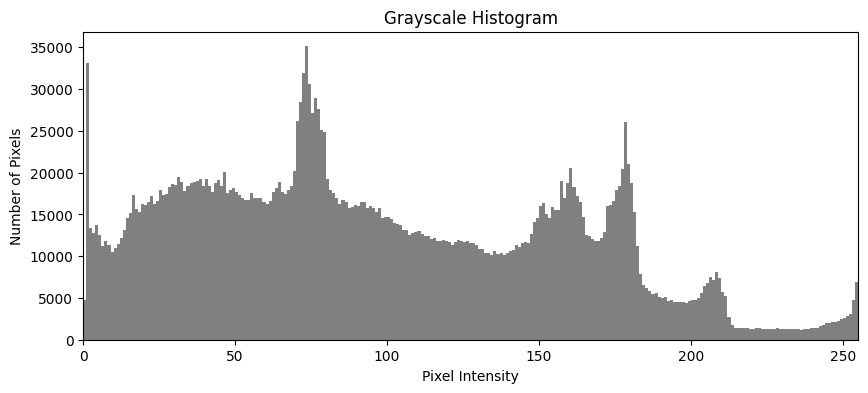

In [2]:
plt.figure(figsize=(10, 4))

plt.hist(gray.ravel(), bins=256, range=(0, 256), color="gray")

plt.title("Grayscale Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Number of Pixels")
plt.xlim(0, 255)
plt.show()

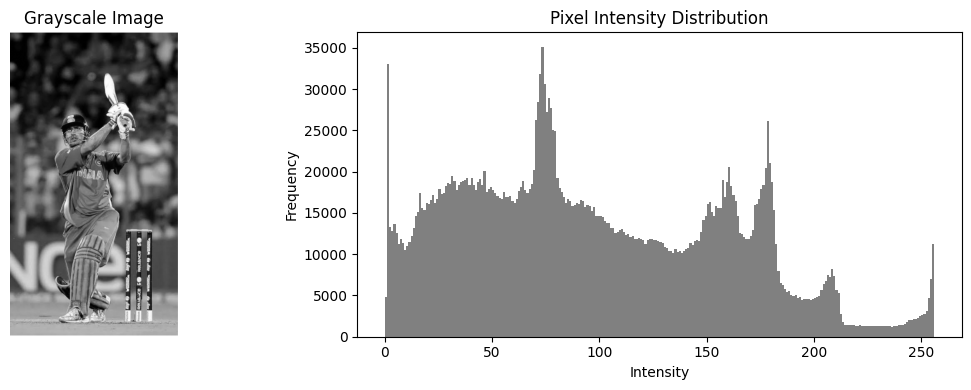

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].imshow(gray, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Grayscale Image")
axes[0].axis("off")

axes[1].hist(gray.ravel(), bins=256, range=(0, 256), color="gray")
axes[1].set_title("Pixel Intensity Distribution")
axes[1].set_xlabel("Intensity")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

# Normal Histogram vs Histogram Equalization vs CLAHE

## 1. Normal Histogram
- Represents the distribution of pixel intensities in an image.
- For an 8-bit grayscale image, pixel values range from **0 to 255**.
- Helps analyze image brightness and contrast.
- Does not modify the image.

## 2. Histogram Equalization
- Improves **global contrast** by remapping pixel intensities.
- Uses the Cumulative Distribution Function (CDF).
- Applies enhancement to the entire image.
- May amplify noise or make some regions look unnatural.

**OpenCV:** `cv2.equalizeHist(img)`

## 3. CLAHE
- Stands for **Contrast Limited Adaptive Histogram Equalization**.
- Improves **local contrast** by processing small image regions called tiles.
- Clips histogram peaks to limit excessive contrast amplification.
- Uses interpolation between tiles to reduce visible boundaries.
- Often preserves local details better in images with uneven lighting.

**OpenCV:**
```python
clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

result = clahe.apply(img)
```

## 4. Key Differences

| Feature | Normal Histogram | Histogram Equalization | CLAHE |
|---|---|---|---|
| Purpose | Analyze intensity distribution | Improve global contrast | Improve local contrast |
| Processing | No image enhancement | Entire image | Local tiles |
| Pixel values | Unchanged | Remapped | Remapped locally |
| Noise amplification | Not applicable | Can occur | Limited, not eliminated |
| Uneven lighting | Analysis only | May be less effective | Often more effective |

## 5. Applications
- **Normal histogram:** Image analysis and brightness inspection.
- **Histogram equalization:** Enhancing low-contrast images.
- **CLAHE:** Medical imaging, low-light images, and images with uneven illumination.

## Key Takeaway
- **Normal histogram:** Understand the pixel intensity distribution.
- **Histogram equalization:** Improve global contrast.
- **CLAHE:** Improve local contrast while limiting excessive enhancement.

**Note:** Both histogram equalization and CLAHE can be applied to grayscale images. For color images, apply enhancement to an appropriate luminance channel to reduce color distortion.


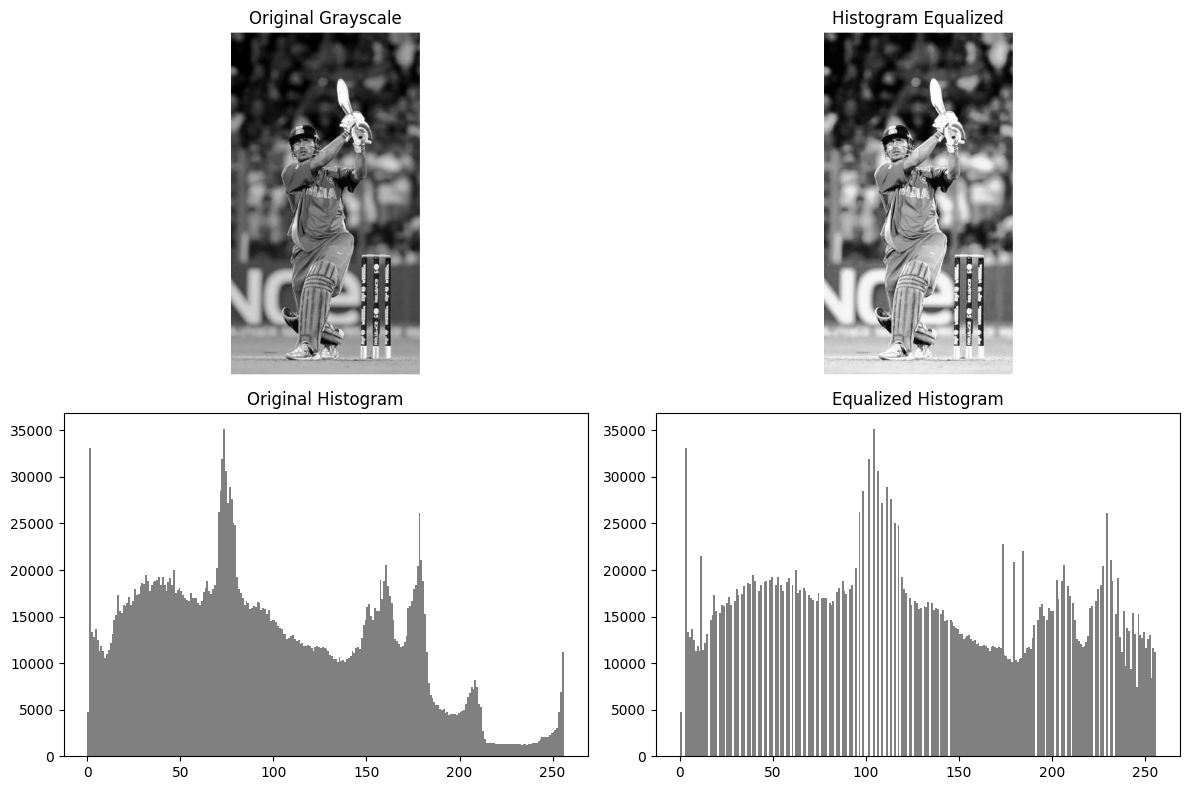

In [4]:
equalized = cv2.equalizeHist(gray)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].imshow(gray, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title("Original Grayscale")
axes[0, 0].axis("off")

axes[0, 1].imshow(equalized, cmap="gray", vmin=0, vmax=255)
axes[0, 1].set_title("Histogram Equalized")
axes[0, 1].axis("off")

axes[1, 0].hist(gray.ravel(), bins=256, range=(0, 256), color="gray")
axes[1, 0].set_title("Original Histogram")

axes[1, 1].hist(equalized.ravel(), bins=256, range=(0, 256), color="gray")
axes[1, 1].set_title("Equalized Histogram")

plt.tight_layout()
plt.show()

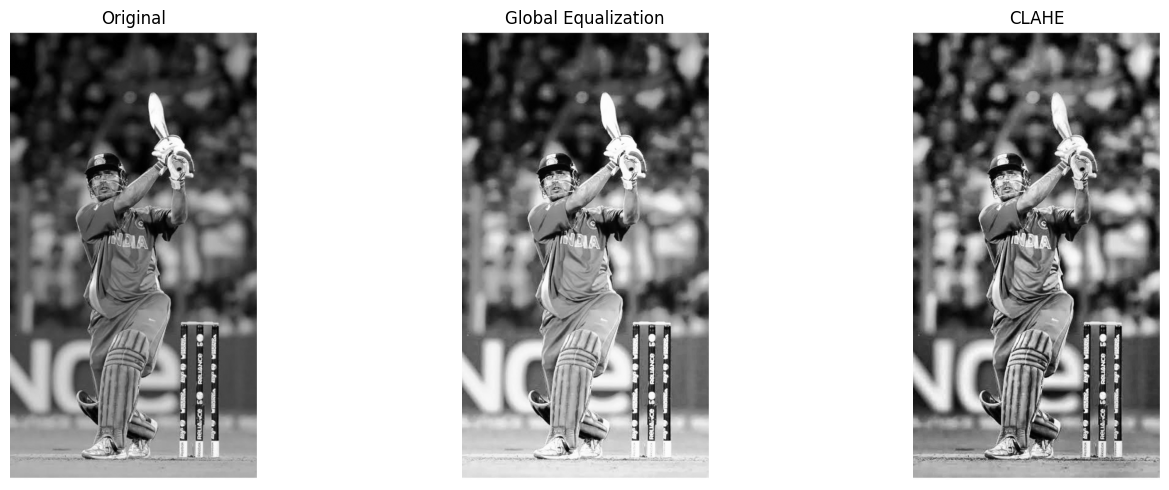

In [5]:
# Apply CLAHE for local contrast enhancement

clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

clahe_result = clahe.apply(gray)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(gray, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original")

axes[1].imshow(equalized, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Global Equalization")

axes[2].imshow(clahe_result, cmap="gray", vmin=0, vmax=255)
axes[2].set_title("CLAHE")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.savefig('images/2. Histogram.jpg')
plt.show()

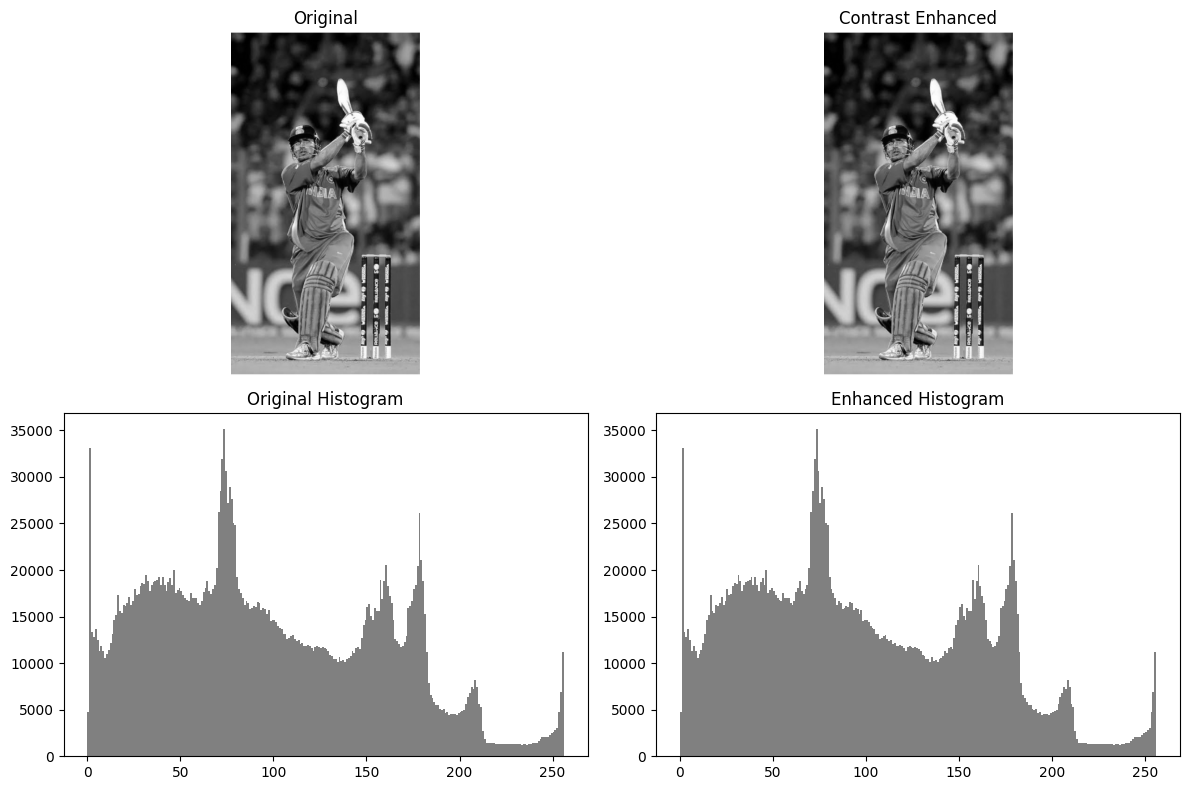

In [6]:
# Contrast enhancement

enhanced = cv2.normalize(
    gray,
    None,
    alpha=0,
    beta=255,
    norm_type=cv2.NORM_MINMAX
)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].imshow(gray, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title("Original")
axes[0, 0].axis("off")

axes[0, 1].imshow(enhanced, cmap="gray", vmin=0, vmax=255)
axes[0, 1].set_title("Contrast Enhanced")
axes[0, 1].axis("off")

axes[1, 0].hist(gray.ravel(), bins=256, range=(0, 256), color="gray")
axes[1, 0].set_title("Original Histogram")

axes[1, 1].hist(enhanced.ravel(), bins=256, range=(0, 256), color="gray")
axes[1, 1].set_title("Enhanced Histogram")

plt.tight_layout()
plt.show()

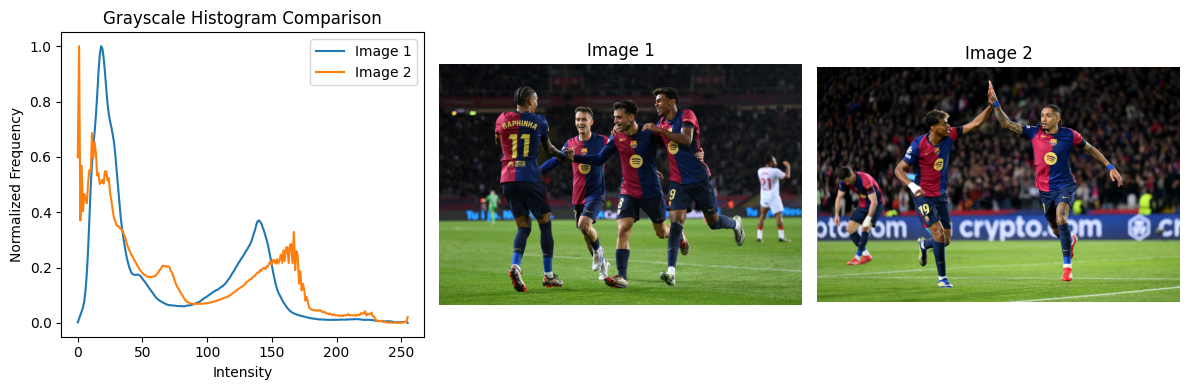

In [7]:
image1 = cv2.imread("Mini Project/Raw/image 1.jpg")
image2 = cv2.imread("Mini Project/Raw/image 2.jpg")

if image1 is None or image2 is None:
    raise FileNotFoundError("Could not load one or both images.")

gray1 = cv2.cvtColor(image1, cv2.COLOR_BGR2GRAY)
gray2 = cv2.cvtColor(image2, cv2.COLOR_BGR2GRAY)

hist1 = cv2.calcHist([gray1], [0], None, [256], [0, 256])
hist2 = cv2.calcHist([gray2], [0], None, [256], [0, 256])

# Normalize histograms for comparison
hist1 = cv2.normalize(hist1, None, alpha=0, beta=1, norm_type=cv2.NORM_MINMAX)
hist2 = cv2.normalize(hist2, None, alpha=0, beta=1, norm_type=cv2.NORM_MINMAX)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].plot(hist1, label="Image 1")
axes[0].plot(hist2, label="Image 2")
axes[0].set_title("Grayscale Histogram Comparison")
axes[0].set_xlabel("Intensity")
axes[0].set_ylabel("Normalized Frequency")
axes[0].legend()

axes[1].imshow(cv2.cvtColor(image1, cv2.COLOR_BGR2RGB))
axes[1].set_title("Image 1")
axes[1].axis("off")

axes[2].imshow(cv2.cvtColor(image2, cv2.COLOR_BGR2RGB))
axes[2].set_title("Image 2")
axes[2].axis("off")

plt.tight_layout()
plt.show()